# Statistics with Pingouin

[**Pingouin**](https://pingouin-stats.org/index.html) is a statistics package in Python that wraps pandas and [scipy-stats](https://docs.scipy.org/doc/scipy/reference/stats.html), creating more-complete statistics reports and presenting the results in a readable way.

## Setup

### Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import pingouin as pg
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import xarray as xr

## T-Tests

T-tests compare the means of two samples of data generated from a normally-distributed population and compute the probability that they have the same mean.

| Code | Statistical Test | Description |
| --- | --- | --- |
| `pg.ttest(x, 0)` | One-Sampled T-Test | "Is the mean of my data unlikely to be zero?" |
| `pg.ttest(x, y)` | Independent-Samples T-Test | "Do the means of x and y indicate they are unlikely to be from the same distribution?" |
| `pg.ttest(x, y, paired=True)` | Paired-Samples T-test | "Comparing each value directly to its neighbor, are the mean differences of x and y's data unlikely to be zero?" |

Let's do some analysis on some fake data to get a feel for these two statistics tools.



#### **Exercises**

Generate the Data: Run the code below to create the dataset `df`.  This will create data from 4 variables: A, B, C, and D, and our goal will be to work out if we can find evidence that of these variables contain data from a different distribution than another.

<Axes: >

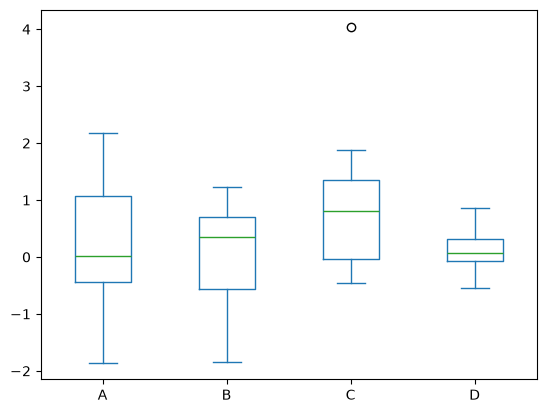

In [4]:
randomizer = np.random.RandomState(17)  # Makes sure the pseudorandom number generators reproduce the same data for us all.
df = pd.DataFrame()
df['A'] = randomizer.normal(0, 1, size=20)
df['B'] = randomizer.normal(0.2, 1, size=20)
df['C'] = randomizer.normal(0.7, 1, size=20)
df['D'] = df.A * 0.3 + randomizer.normal(0, 0.3, size=20)
df.plot.box()

### Analyze the Data with T-Tests in Pingouin

**Example**: **A vs 0, One-Sampled T-Test**: Is the mean of the normally-distributed population that the dataset A is generated from unlikely to be zero?

In [ ]:
pg.ttest(df['A'], 0)

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,0.378652,19,two-sided,0.709144,"[-0.45, 0.65]",0.084669,0.248,0.064966


**Exercise**: **B vs 1, One-Sampled T-Test**: Is the mean of the normally-distributed population that the dataset B is generated from unlikely to be one?

**A vs B, Independent Samples T-Test**: Is the mean of the normally-distributed population that the dataset `A` is generated from unlikely to be the same as the mean of the normally-distributed population that the dataset `B` is generated from?

In [ ]:
pg.ttest(df['A'], df['B'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-0.137189,38,two-sided,0.891606,"[-0.7, 0.61]",0.043383,0.311,0.052052


**Exercise**: **A vs C, Independent Samples T-Test**: Is the mean of the normally-distributed population that the dataset `A` is generated from unlikely to be the same as the mean of the normally-distributed population that the dataset `C` is generated from?

**Exercise**: **A vs C, Paired Samples T-Test**: Is the mean of the differences between each pair of samples generated from the two normally-distributed populations `A` and `C`  unlikely to be 0?

**Exercise**: **A vs D, Paired Samples T-Test**: Is the mean of the differences between each pair of samples generated from the two normally-distributed populations `A` and `D`  unlikely to be 0?

## T-Tests on Real-World Data: Pupil Position Analysis

In the experiments reported by [Steinmetz et al, 2019 in Nature](https://www.nature.com/articles/s41586-019-1787-x), mice performed a discrimination task where they moved the position of a stimulus using a steering wheel. During the experiment, a camera recorded the pupil position of the subject in the x and y directions.

| Code | Description |
| :--- | :--- |
| `np.logical_and(condition1, condition2)` | Element-wise logical AND of two boolean arrays |
| `sns.kdeplot(data, label='name')` | Create a kernel density estimate plot |
| `plt.axvline(x, color, linestyle)` | Add a vertical line to the plot |
| `plt.legend()` | Display the legend on the plot |
| `pg.ttest(x, y, paired=True/False)` | Perform t-test (paired or independent) |

### Load and Filter the Data

Run the code below, which loads the file, extracts the variables, filters the data, and transforms it into a dataframe.

#### **Exercises**

In [6]:
dset = xr.load_dataset('data/steinmetz_2017-01-08_Muller.nc')
dd = dset[['pupil_x', 'pupil_y', 'contrast_left', 'contrast_right', 'response_type']]
dd = dd.where(
    (dset.active_trials==True) 
    & (dset.response_type != 0)
    & (dset.time >= 0.5)
    & (dset.time <= 1.3)
    , drop=True)
dd['contrast_diff'] = dd['contrast_right'] - dd['contrast_left']
trials = dd.median(dim='time')
rdf = trials.to_dataframe()
rdf.head()

,pupil_x,pupil_y,contrast_left,contrast_right,response_type,contrast_diff
trial,,,,,,
1,-1.019465,0.754972,50.0,0.0,1.0,-50.0
2,-0.184417,0.509199,0.0,50.0,-1.0,50.0
3,0.799240,-0.486496,100.0,25.0,1.0,-75.0
4,-0.294746,-0.218956,0.0,100.0,-1.0,100.0
5,-0.367058,-0.259306,50.0,50.0,1.0,0.0


Extract data from the dataframe `rdf`, plot its distribution(s), and use a t-test to answer the questions below:

**Example**: For the trials where `contrast_left` was greater or equal to 50 and `contrast_right` was 0, was the average `pupil_x` position for the trial zero?

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,3.447425,24,two-sided,0.002098,"[0.22, 0.88]",0.689485,18.185,0.910939


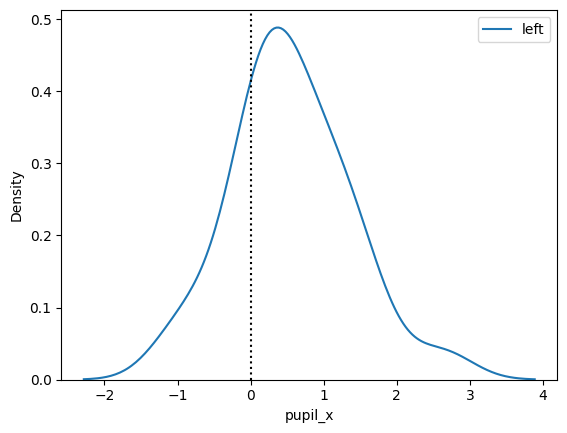

In [ ]:
left = rdf[(rdf.contrast_left >= 50) & (rdf.contrast_right == 0)]
sns.kdeplot(left.pupil_x, label='left')
plt.axvline(0, color='black', linestyle='dotted')
plt.legend()
pg.ttest(left.pupil_x, 0)

**Exercise**: Where the mice looking at the stimulus that was presented?  In trials where there was only one stimulus present (i.e. `contrast_left` or `contrast_right` was zero), and the stimulus had at least a contrast level of 50 (quite visible), was there a difference in the average `pupil_x` position?

**Exercise**: As a sanity check, was there a difference in vertical eye position between the left-stimulus trials and the right-stimulus trials?  In trials where there was only one stimulus present (i.e. `contrast_left` or `contrast_right` was zero), and the stimulus had at least a contrast level of 50 (quite visible), was there a difference in the average `pupil_y` position?

**Exercise**: Did mice look in the direction they turned the wheel?  Was there a difference in average `pupil_x` position between left-turning trials (i.e. `response_type` is -1) and right-turning trials (i.e. `response_type` is 1)?

**Exercise**: As a sanity check, did vertical eye position matter?  Was there a difference in average `pupil_y` position between left-turning trials (i.e. `response_type` is -1) and right-turning trials (i.e. `response_type` is 1)?

## Working with Long DataFrames

If data is organized as a long dataframe, it is also possible to have `pingouin` simply do all the comparisons between the groups.  Not only is this very convenient; it also makes it possible for pingouin to do richer analyses.

| Code | Description |
| --- | --- |
| `pg.anova(data=dfl, dv='value', between=['variable'], detailed=True)` | Analysis of Variance (ANOVA). |
| `pg.pairwise_tests(data=dfl, dv='value', between='variable', padjust='fdr_bh', parametric=True/False)` | Pairwise T-tests. |  

Run the cell below to melt the DataFrame `df` into a long DataFrame `dfl` to be used in the following exercises.

#### **Exercises**

In [ ]:
dfl = df.melt(ignore_index=False).reset_index()
dfl.sample(5)

,index,variable,value
39,19,B,-1.835995
6,6,A,-0.111698
29,9,B,0.549896
27,7,B,0.359991
5,5,A,1.886639


**Example**: Before doing pairwise tests, it's often helpful to run an ANOVA analysis, which can tell you quickly whether a pairwise difference exists within a collection of potential pairs.  Below, run an ANOVA test comparing the dv 'value' between values of 'variable' to see if a significant difference is expected.

In [ ]:
pg.anova(dfl, dv='value', between=['variable'], detailed=True, )

,Source,SS,DF,MS,F,p-unc,np2
0,variable,7.259916,3,2.419972,2.851046,0.042862,0.101157
1,Within,64.508906,76,0.848801,NaN,NaN,NaN


**Exercise**: Do a t-tests for every possible pairwise comparison of "variable" (e.g. "A" vs "B", "A" vs "C", etc).  (Tip: it works similar to the `pg.anova` function.)

**Exercise**: Repeat the tests, but this time, adjust the p-value to compensate for multiple comparisons using the 'fdr' method.  Are the significant differences still significant?  How do the corrected p-values compare to the uncorrected p-values?

**Exercise**: Do a pairwise test again on the long dataframe, comparing the value of 'value' between each value 'variable'.  This time, use a non-parametric comparison (not assuming a normal distribution of each variable), and still adjust for multiple comparisons.  Are your results the same?

Use the `rdf` dataframe from the pupil measurement data.  Is there a significant different in average horizontal position, when comparing all the `contrast_diff` levels in the study pairwise?

## A Gallery of Plots : 2D Histograms with `sns.jointplot()`

Let's try out a few different plots, for comparing two different continuous variables' distributions.

| Code | Description |
| ---  | --- |
| `sns.jointplot(df, x='colA', y='colB')` | Makes a joint histogram |
| `sns.jointplot(df, x='colA', y='colB', kind='kde')` | Makes a joint plot with kernel density estimate |
| `sns.jointplot(df, x='colA', y='colB', kind='hex')` | Makes a joint plot with hexagonal bins |
| `sns.jointplot(df, x='colA', y='colB', hue='colC')` | Makes a joint plot colored by a categorical variable |

#### **Exercises**

**Example**: Make a joint plot comparing the `pupil_x` and `pupil_y` variables.

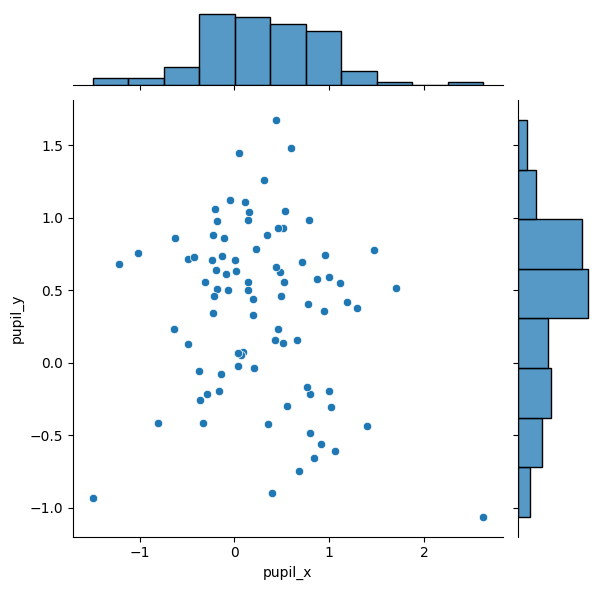

In [ ]:
sns.jointplot(rdf, x="pupil_x", y="pupil_y");

**Exercise**: Make a joint plot comparing the `pupil_x` and `pupil_y` variables, using `kind='kde'`.

**Exercise**: Make a joint plot comparing the `pupil_x` and `pupil_y` variables, using `kind='kde'` and setting `hue` to `'response_type'`.

**Exercise**: Make a joint plot comparing the `pupil_x` and `pupil_y` variables, using `kind='hex'`.

## Further Reading

Nice article on Pingouin here: https://towardsdatascience.com/the-new-kid-on-the-statistics-in-python-block-pingouin-6b353a1db57c

Nice summary of the different effect size metrics and when to pick which: https://www.socscistatistics.com/effectsize/default3.aspx

## Extra: Correlations and Simpson's Paradox

| Code | Description |
| --- | --- |
| `pg.corr(A, B)` | The correlation between variables A and B |
| `pg.pairwise_corr(flowers)` | Pairwise correlations |
| `df.plot.scatter(x='A', y='B')` | Make a scatter plot |
| `sns.lmplot(data=df, x='Col1', y='Col2')` | Make a scatter plot with a regression line |
| `sns.lmplot(data=df, x='Col1', y='Col2', hue='Col3')` | Make a scatter plot with a regression line, colored by a categorical variable |

Run the cell below to download the iris dataset for this section:

#### **Exercises**

In [ ]:
from bokeh.sampledata import iris
flowers = iris.flowers
flowers.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


**Example**: Is there a correlation between flowers' sepal widths and their petal lengths?

In [ ]:
pg.corr(flowers['sepal_width'], flowers['petal_length'])

,n,r,CI95%,p-val,BF10,power
pearson,150,-0.42844,"[-0.55, -0.29]",4.513314e-08,2.762e+05,0.999847


**Exercise**: Use seaborn's `lmplot()` function to plot a regression line showing the sepal widths and petal lengths.  Does the direction of this line match the results?  Looking closely at the data's distribution, what is missing from this story?

**Exercise**: This time factor in the `species` variable into the `lmplot()` visualization.  What kind of relationship do you see between `sepal_width` and `petal_length` now?

#### Demo

**Example**: What's happening here is that a third variable, `"species"`, is influencing both the petal and the sepal shape; this effect is called "Simpson's Paradox".   Unfortunately, at this time (as far as I know) pengouin doesn't have a way to split a correlation into multiple groups; one way to do this, though, is to use a `df.groupby()` analysis, concatenating the results together.

In [ ]:
analyses = []
for name, group in flowers.groupby('species'):
    analysis = pg.corr(group['sepal_width'], group['petal_length'])
    analysis['name'] = name
    analyses.append(analysis)
results = pd.concat(analyses)
results

,n,r,CI95%,p-val,BF10,power,name
pearson,50,0.177700,"[-0.11, 0.43]",0.216979,0.37,0.236771,setosa
pearson,50,0.560522,"[0.33, 0.73]",0.000023,1061.04,0.992245,versicolor
pearson,50,0.401045,"[0.14, 0.61]",0.003898,10.094,0.836041,virginica


To summarize, accounting for the right variables is a big part of science; we should always be aware that the patterns we see in our data can be turned completely upside down when new aspects of a problem are understood and factored in!